In [5]:
import pandas as pd
df = pd.read_excel("/Users/lzh/Downloads/NUS Y4S1 Downloads/BT2102/Assignment 3/data/raw/BeijingHousingPrices.xlsx", sheet_name=0)  

In [6]:
import matplotlib.pyplot as plt

In [7]:
district_map = {
    1: "Dongcheng",
    2: "Fengtai",
    3: "Tongzhou",
    4: "Daxing",
    5: "Fangshan",
    6: "Changping",
    7: "Chaoyang",
    8: "Haidian",
    9: "Shijingshan",
    10: "Xicheng",
    11: "Pinggu",
    12: "Mentougou",
    13: "Shunyi",
}

df["district_name"] = df["district"].map(district_map)

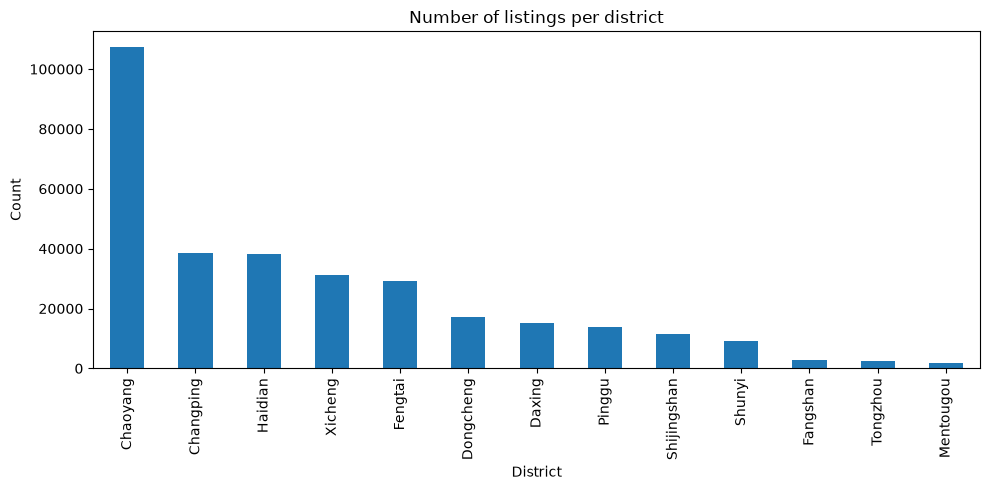

In [8]:
df["district_name"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of listings per district")
plt.xlabel("District")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [10]:
df["buildingType"].unique()

array([1.   , 4.   , 3.   ,   nan, 2.   , 0.5  , 0.333, 0.125, 0.25 ,
       0.429, 0.048, 0.375, 0.667])

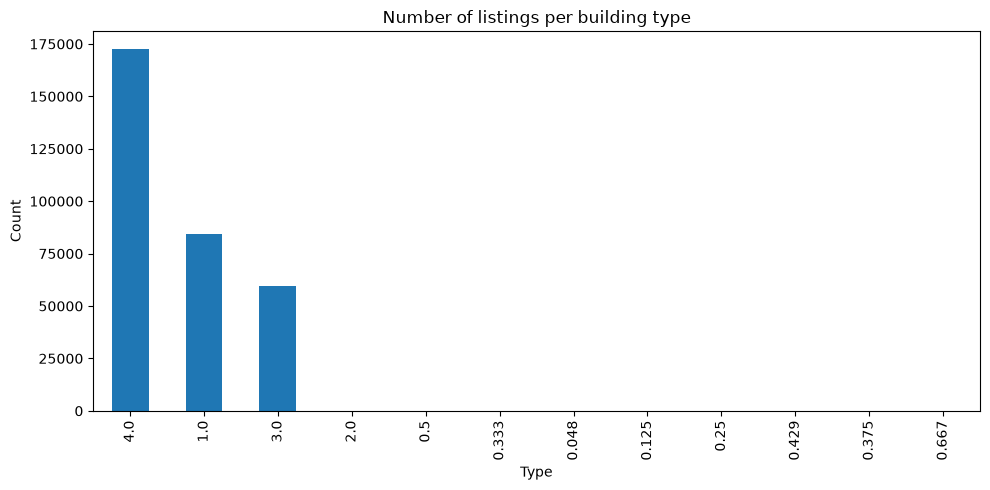

In [11]:
df["buildingType"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of listings per building type")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

In [6]:
df[["story_type", "story"]] = df["floor"].str.split(" ", n=1, expand=True)

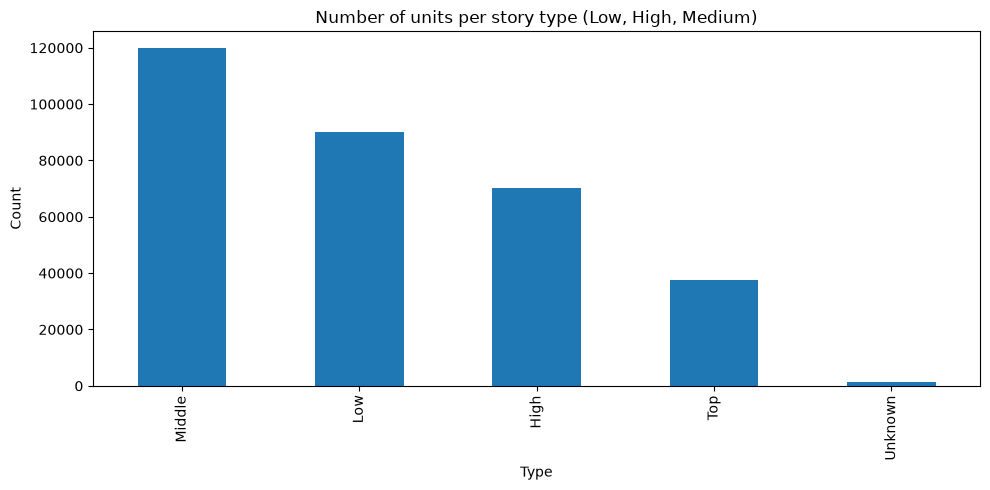

In [9]:
df["story_type"].value_counts().plot(kind="bar", figsize=(10, 5))
plt.title("Number of units per story type (Low, High, Medium)")
plt.xlabel("Type")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

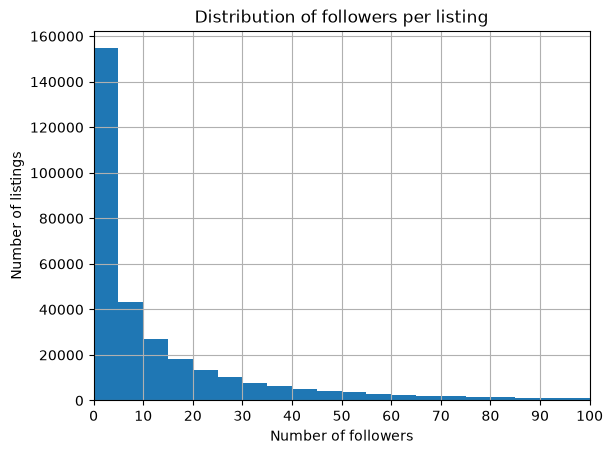

In [14]:
ax = df["followers"].hist(bins=range(0, 101, 5))
ax.set_xlim(0, 100)
ax.set_xticks(range(0, 101, 10))   # markers at 0, 10, 20, ... 100
ax.set_title("Distribution of followers per listing")
ax.set_xlabel("Number of followers")
ax.set_ylabel("Number of listings")
plt.show()

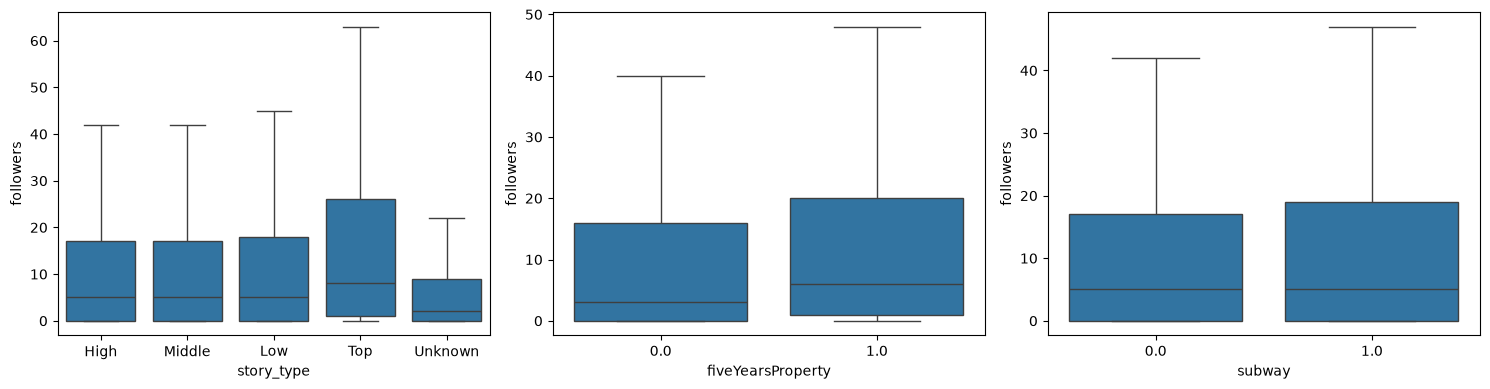

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["story_type", "fiveYearsProperty", "subway"]):
    sns.boxplot(data=df, x=col, y="followers", showfliers=False, ax=ax)
plt.tight_layout()
plt.show()

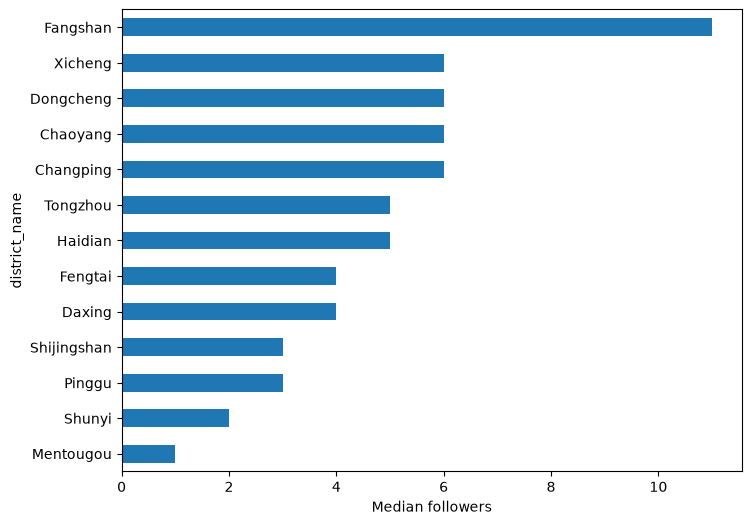

In [17]:
df.groupby("district_name")["followers"].median().sort_values().plot(kind="barh", figsize=(8, 6))
plt.xlabel("Median followers")
plt.show()

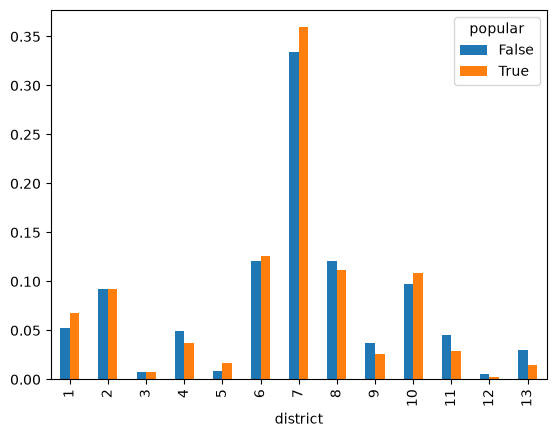

In [21]:
df["popular"] = df["followers"] >= df["followers"].quantile(0.9)   # has follower count in the top 10% most followed listings

pd.crosstab(df["district"], df["popular"], normalize="columns").plot(kind="bar")
plt.show()